In [1]:
# Imports
import json
from matplotlib import pyplot
from matplotlib.ticker import ScalarFormatter


In [2]:
# Load data files

with open('../../data/output/steady_state.json', 'r') as file:
    steady_state = json.load(file)

with open('../../data/output/perturbation_down.json', 'r') as file:
    perturbation_down = json.load(file)

with open('../../data/output/perturbation_up.json', 'r') as file:
    perturbation_up = json.load(file)


[3337500.0, 3337500.0]
[0.0, 3337500.0]


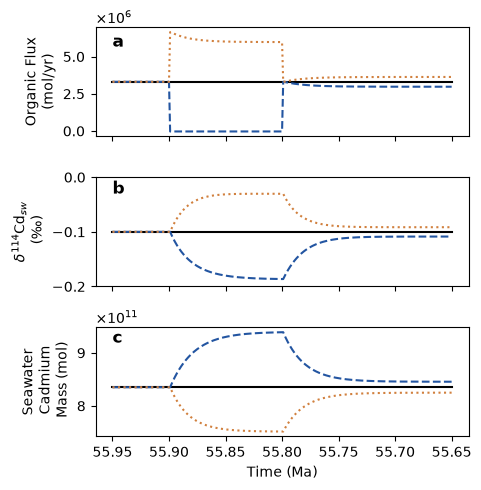

In [8]:
# Plot
colours = {"steady":"#000000",
                            "perturb_down":"#2355a1",
                            "perturb_up":"#d1803e"}
styles = {"steady":"-",
                            "perturb_down":"--",
                            "perturb_up":":"}

formatter_0 = ScalarFormatter(useMathText=True)
formatter_0.set_scientific(True)

formatter_1 = ScalarFormatter(useMathText=True)
formatter_1.set_scientific(True)

print([min(steady_state['organic_mass']),max(steady_state['organic_mass'])])
print([min(perturbation_down['organic_mass']),max(perturbation_down['organic_mass'])])

figure,axes = pyplot.subplots(3,1,figsize=(5,5),sharex=True)
axes[0].plot(steady_state['time'],steady_state['organic_mass'],zorder=3,color=colours["steady"],linestyle=styles["steady"])
axes[0].plot(steady_state['time'],perturbation_down['organic_mass'],zorder=3,color=colours["perturb_down"],linestyle=styles["perturb_down"])
axes[0].plot(steady_state['time'],perturbation_up['organic_mass'],zorder=3,color=colours["perturb_up"],linestyle=styles["perturb_up"])

axes[1].plot(steady_state['time'],steady_state['seawater_δ114Cd'],zorder=3,color=colours["steady"],linestyle=styles["steady"])
axes[1].plot(steady_state['time'],perturbation_down['seawater_δ114Cd'],zorder=3,color=colours["perturb_down"],linestyle=styles["perturb_down"])
axes[1].plot(steady_state['time'],perturbation_up['seawater_δ114Cd'],zorder=3,color=colours["perturb_up"],linestyle=styles["perturb_up"])

axes[2].plot(steady_state['time'],steady_state['seawater_mass'],zorder=3,color=colours["steady"],linestyle=styles["steady"])
axes[2].plot(steady_state['time'],perturbation_down['seawater_mass'],zorder=3,color=colours["perturb_down"],linestyle=styles["perturb_down"])
axes[2].plot(steady_state['time'],perturbation_up['seawater_mass'],zorder=3,color=colours["perturb_up"],linestyle=styles["perturb_up"])

axes[0].invert_xaxis()
axes[1].set_ylim((-0.2,0.0))

axes[0].yaxis.set_major_formatter(formatter_0)
axes[2].yaxis.set_major_formatter(formatter_1)

axes[0].set_ylabel("Organic Flux\n(mol/yr)")
axes[1].set_ylabel("$\\delta^{114}$Cd$_{sw}$\n (‰)")
axes[2].set_ylabel("Seawater\n Cadmium\n Mass (mol)")

axes[2].set_xlabel("Time (Ma)")
# axes[0].set_ylim((-0.5,0.5))

# Add a, b, c labels
axes[0].text(55.95, 5.7e6, 'a', fontsize=12, fontweight='bold')
axes[1].text(55.95, -0.03, 'b', fontsize=12, fontweight='bold')
axes[2].text(55.95, 9.2e11, 'c', fontsize=12, fontweight='bold')

figure.tight_layout()
pyplot.show()

figure.savefig('../../figures/forward_simulations.png',dpi=300)
figure.savefig('../../figures/figure_4.svg',dpi=600)